# SciPy Interpolation: Cubic Spline vs. PCHIP
Zunairah Abbasi

## Introduction
SciPy is an open source Python library for scientific and numerical computing. It provides tools for tasks such as integration, optimization, interpolation, and linear algebra. Its primary audience includes scientists, engineers, researchers, and students who need numerical methods for their work. For this project, I focus on its interpolation tools, which estimate values between known data points.

## Stakeholders and community
SciPy is used by scientists, engineers, researchers, and students. They need results they can trust, but what matters most depends on what they are doing. In my example, someone working with a total that should never decrease might choose PCHIP. Someone who needs continuous second derivatives might choose a cubic spline. Clear documentation and examples also help users understand which method to use.

SciPy’s developers include volunteers and people who work on it as part of their jobs. Quansight and Los Alamos National Laboratory support the project by employing contributors. NumFOCUS manages donations and provides administrative and legal support. Keeping SciPy running takes funding, along with time to fix bugs, review changes, and maintain the documentation.

Source: https://scipy.org/about/

## Development process and priorities
SciPy contributors use GitHub issues and pull requests to report bugs, suggest changes, and discuss ideas. Bigger decisions are discussed on the SciPy development forum. A developer submits a code change through a pull request, and another developer reviews it. Developers are also expected to include tests to check that their changes work as intended.

Before adding a feature, SciPy considers how useful it would be and how much work it would take to maintain. Someone needs to write the code, and someone with the right knowledge needs time to review it. The developer guide explains that finding a reviewer can be difficult. This means that even a useful idea may have to wait because developers also need time to fix bugs and maintain existing code.

Source: https://scipy.github.io/devdocs/dev/core-dev/index.html


### Example: PCHIP and complex inputs
In SciPy issue #19739, developers discussed a problem with PCHIP and complex numbers. PCHIP uses the signs of slopes to help preserve the shape of real data, but that logic caused problems with complex inputs. Developers discussed whether to explain the problem in the documentation or stop accepting those inputs. They decided to warn users first and remove support later. The pull request adding the warning was merged on January 3, 2024.

This shows that fixing a numerical problem also means thinking about people who already use the software. The warning gave users time to update their code before the behavior changed.

Sources: https://github.com/scipy/scipy/issues/19739, https://github.com/scipy/scipy/pull/19752

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy.interpolate import CubicSpline, PchipInterpolator

print("SciPy version:", scipy.__version__)

SciPy version: 1.14.1


## Tutorial example

I ran the cubic spline example from the SciPy tutorial at x = 2.5, then changed the evaluation point to x = 3.5.

Source: https://docs.scipy.org/doc/scipy/tutorial/interpolate/1D.html

In [2]:
tutorial_spline = CubicSpline(
    [1, 2, 3, 4, 5, 6],
    [1, 4, 8, 16, 25, 36]
)

print("Estimate at x = 2.5:", tutorial_spline(2.5))

Estimate at x = 2.5: 5.570833333333334


In [3]:
tutorial_spline = CubicSpline(
    [1, 2, 3, 4, 5, 6],
    [1, 4, 8, 16, 25, 36]
)

print("Estimate at x = 3.5:", tutorial_spline(3.5))

Estimate at x = 3.5: 11.6625


## Comparing cubic splines and PCHIP

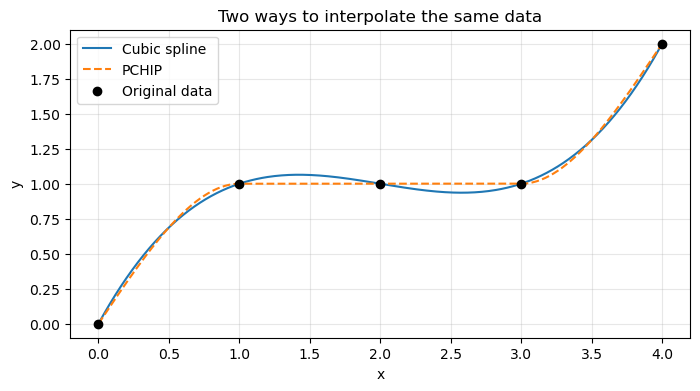

In [4]:
# Original data with a flat section
x = np.array([0, 1, 2, 3, 4])
y = np.array([0, 1, 1, 1, 2])

# Points where we want estimates
x_dense = np.linspace(0, 4, 401)

cubic = CubicSpline(x, y)
pchip = PchipInterpolator(x, y)

plt.figure(figsize=(8, 4))
plt.plot(x_dense, cubic(x_dense), label="Cubic spline")
plt.plot(x_dense, pchip(x_dense), "--", label="PCHIP")
plt.scatter(x, y, color="black", label="Original data", zorder=3)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Two ways to interpolate the same data")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [5]:
# Use the original data
x_flat = np.array([0, 1, 2, 3, 4])
y_flat = np.array([0, 1, 1, 1, 2])

# Check points in the flat section
x_check = np.linspace(1, 3, 2001)

cubic_flat = CubicSpline(x_flat, y_flat)
pchip_flat = PchipInterpolator(x_flat, y_flat)

# Find the largest distance from 1 for each curve
cubic_difference = np.max(np.abs(cubic_flat(x_check) - 1))
pchip_difference = np.max(np.abs(pchip_flat(x_check) - 1))

print("Cubic spline:", round(cubic_difference, 6))
print("PCHIP:", round(pchip_difference, 6))

Cubic spline: 0.06415
PCHIP: 0.0


Measuring the flat region

I checked 2,001 points between x = 1 and x = 3 to see how far each curve moved away from 1. The largest difference was about 0.06415 for the cubic spline and zero for PCHIP. This matches what I saw in the plot: PCHIP stayed flat, while the cubic spline curved above and below 1. This would matter if I needed the curve to preserve a flat part of the data. It still does not tell me which curve is closer to the true values between the points.

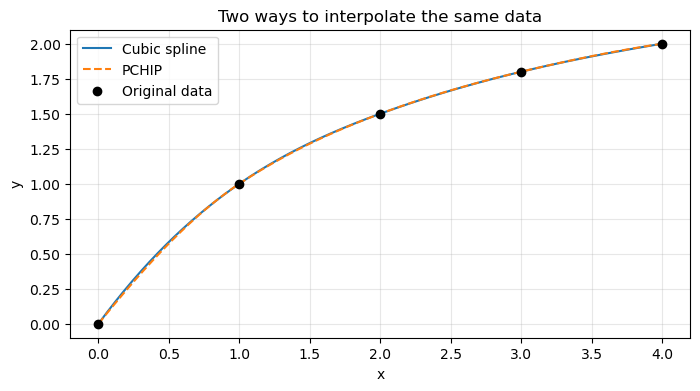

In [6]:
# Changed the data so the values keep increasing
x = np.array([0, 1, 2, 3, 4])
y = np.array([0, 1, 1.5, 1.8, 2])

# Points where we want estimates
x_dense = np.linspace(0, 4, 401)

cubic = CubicSpline(x, y)
pchip = PchipInterpolator(x, y)

plt.figure(figsize=(8, 4))
plt.plot(x_dense, cubic(x_dense), label="Cubic spline")
plt.plot(x_dense, pchip(x_dense), "--", label="PCHIP")
plt.scatter(x, y, color="black", label="Original data", zorder=3)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Two ways to interpolate the same data")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## What changed in the data: 

In the first dataset, the values stayed at 1 from x = 1 to x = 3. The cubic spline curved a little above and below 1, while PCHIP stayed flat. I then changed the data so the values kept increasing, and the two curves looked almost the same. If the data represented a total that should never decrease, I would choose PCHIP because it does not add a decrease between the points. Both methods go through the original points, but this alone does not tell us which is more accurate between them.



## Accuracy, conditioning, and stability
Accuracy: Both methods go through the original points, but I do not know the true values between them. My measurement shows how well each curve preserves the flat section. To check accuracy, I could use data from a known function and compare the estimates with its actual values.

Conditioning: Conditioning is about how sensitive a problem is to small changes in the input. I could explore this by changing one y-value slightly and checking how much the curve changes. I would compare the size of the change in the data with the change in the result. I have not tested this yet.

Stability: Numerical stability is about how the algorithm handles errors from the computation, such as rounding. An unstable algorithm can introduce much more error than the problem’s sensitivity would explain. The cubic spline’s wiggle comes from the shape of the spline and could happen even without rounding errors. This means my plot does not show that the cubic spline is numerically unstable or that PCHIP is more stable.

Sources: https://fncbook.com/conditioning/, https://fncbook.com/stability/, https://docs.scipy.org/doc/scipy/tutorial/interpolate/1D.html

## Cost and comparison metrics

I have not timed these methods, so I cannot say which is faster. To compare speed, I would measure the time to build each interpolator and the time to evaluate it separately. Someone building a curve once and using it many times might care more about evaluation time.

Different users would also care about different measurements:

| User’s goal | Possible x-axis | Possible y-axis |
|---|---|---|
| Get accurate estimates quickly | Construction plus evaluation time in milliseconds | Maximum absolute error against a known function |
| Preserve a flat section | Number of input points | Maximum deviation from the flat value |
| Evaluate a curve at many points | Number of evaluation points | Evaluation time in milliseconds |

For an accuracy comparison, I would use the same known function and evaluation points for both methods. I would also repeat the timing measurements because runtime can vary between runs.

## Question

How do the number of input points and the shape of the data affect the accuracy difference between cubic splines and PCHIP?

## Proposed group experiment

For a group project, I would compare both methods using known functions, such as sin(x) and arctan(10x), on the interval [-1, 1]. These would let me compare a gradually changing curve with one that changes more sharply near the middle.

I would try 5, 10, 20, 50, and 100 evenly spaced input points. For each case, I would evaluate both interpolators at the same 10,001 points and measure the largest absolute difference from the true function. I would also time construction and evaluation, repeat the timings 20 times, and report the median.

I would present the results with:

- A plot of maximum absolute error against the number of input points.
- A plot of maximum absolute error against construction plus evaluation time in milliseconds.

I would make separate plots for each function and show both methods on each plot. For arctan(10x), I would also check whether either interpolated curve decreases anywhere on the evaluation grid, since the true function is increasing.

## Testing

I used SciPy version 1.14.1 and ran the tutorial and comparison examples successfully. I also tried running the fast interpolation tests using `scipy.interpolate.test(label="fast", extra_argv=["-q"])`. After installing pytest and hypothesis, the runner reported that no tests ran. I checked the installation and found that the interpolation test folder was missing. Because of this, I could not verify whether SciPy’s tests pass in this environment.